Malwer Detection

In [ ]:
import os
import hashlib
import math

In [ ]:
def calculate_entropy(file_path):
    """Calculate the entropy of a file."""
    with open(file_path, 'rb') as f:
        byte_arr = list(f.read())
        file_size = len(byte_arr)
        if file_size == 0:
            return 0
        freq_list = [0] * 256
        for b in byte_arr:
            freq_list[b] += 1
        freq_list = [float(x) / file_size for x in freq_list]
        entropy = -sum([p * math.log(p, 2) for p in freq_list if p > 0])
        return entropy


In [ ]:
def get_hashes(file_path):
    """Generate MD5 and SHA256 hashes of a file."""
    with open(file_path, "rb") as f:
        file_bytes = f.read()
        file_md5 = hashlib.md5(file_bytes).hexdigest()
        file_sha256 = hashlib.sha256(file_bytes).hexdigest()
    return file_md5, file_sha256

In [ ]:
def extract_file_features(file_path):
    """Extract the 6 selected features from a file."""
    try:
        # Feature 1: File size (usage_counter)
        file_size = os.path.getsize(file_path)

        # Feature 2: File entropy (fs_excl_counter)
        file_entropy = calculate_entropy(file_path)

        # Feature 3: File is an executable (task_size)
        file_extension = os.path.splitext(file_path)[1]
        is_exe = 1 if file_extension == '.exe' else 0

        # Feature 4: Time since last accessed (end_data)
        last_accessed = os.path.getatime(file_path)

        # Feature 5: Time since last modified (policy)
        last_modified = os.path.getmtime(file_path)

        # Feature 6: Time since file creation (nivcsw)
        created = os.path.getctime(file_path)

        # Combine the 6 features into a dictionary
        features = {
            'usage_counter': file_size,  # usage_counter
            'fs_excl_counter': file_entropy,  # fs_excl_counter
            'task_size': is_exe,  # task_size
            'end_data': last_accessed,  # end_data
            'policy': last_modified,  # policy
            'nivcsw': created  # nivcsw
        }

        return features

    except Exception as e:
        print(f"Error extracting features from {file_path}: {e}")
        return None

In [ ]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import joblib

In [ ]:
# Load the dataset (replace with the path to your CSV file)
dataset = pd.read_csv('malwareDataset.csv')

In [ ]:
# Keep only the top 6 features
selected_features = [
    'usage_counter', 'fs_excl_counter', 'task_size',
    'end_data', 'policy', 'nivcsw'
]

# Drop rows where any of our selected features or the classification target are NaN
cleaned_dataset = dataset.dropna(subset=selected_features + ['classification'])

# Filter the dataset to keep only the selected features and the label
X = cleaned_dataset[selected_features]
y = cleaned_dataset['classification']

# Split dataset into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Scale the selected features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train the Random Forest model
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train_scaled, y_train)

# Save the updated model and scaler
joblib.dump(model, 'malware_detection_model_selected_features.pkl')
joblib.dump(scaler, 'scaler_selected_features.pkl')

print(f"Model successfully trained on {len(X_train)} samples and saved with selected 6 features.")

Model successfully trained on 12875 samples and saved with selected 6 features.


## Advanced Data Understanding & Correlation Analysis

In this section, we analyze the relationships and distributions of the 6 selected training features:
- `usage_counter` (File size)
- `fs_excl_counter` (File entropy)
- `task_size` (Executable indicator)
- `end_data` (Last accessed timestamp proxy)
- `policy` (Last modified timestamp proxy)
- `nivcsw` (File creation timestamp proxy)

We will construct a correlation matrix exclusively for these trained features along with our binary target variable (`classification`).

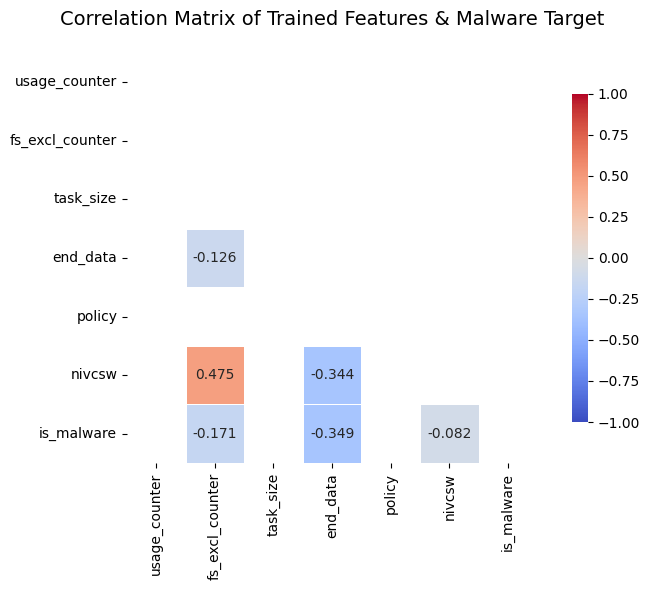

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Create a copy of the cleaned dataset for the analysis
eda_df = cleaned_dataset[selected_features].copy()

# Map target classification to a numeric indicator (1 for malware, 0 for benign)
eda_df['is_malware'] = cleaned_dataset['classification'].map({'malware': 1, 'benign': 0})

# Compute correlation matrix exclusively for the trained features and target
correlation_matrix = eda_df.corr()

# Set up the matplotlib figure
plt.figure(figsize=(8, 6))

# Generate a mask for the upper triangle (optional, for a clean professional look)
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(
    correlation_matrix,
    mask=mask,
    cmap='coolwarm',
    vmax=1.0,
    vmin=-1.0,
    center=0,
    annot=True,
    fmt='.3f',
    square=True,
    linewidths=.5,
    cbar_kws={"shrink": .8}
)

plt.title("Correlation Matrix of Trained Features & Malware Target", fontsize=14, pad=20)
plt.tight_layout()
plt.show()

### Feature Distribution & Density Breakdown
To better understand how these features differ between `benign` and `malware` programs, we plot the density curves of the two most important features detected during the pipeline validation: `nivcsw` (creation time proxy) and `fs_excl_counter` (entropy).

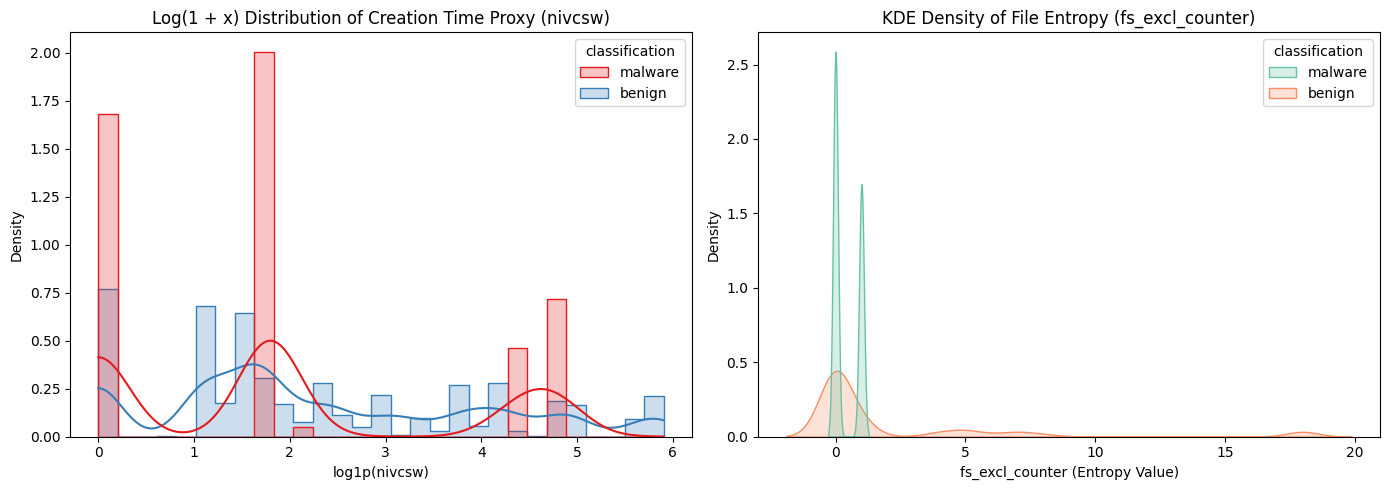

In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Create a copy with non-zero nivcsw values or use a log1p shift to prevent log(0) -> -inf
plot_df = cleaned_dataset[['nivcsw', 'fs_excl_counter', 'classification']].copy()
plot_df['nivcsw_log1p'] = np.log1p(plot_df['nivcsw'])

# Distribution plot for nivcsw (using log1p translation for a stable visual presentation)
sns.histplot(
    data=plot_df,
    x='nivcsw_log1p',
    hue='classification',
    kde=True,
    element='step',
    stat='density',
    common_norm=False,
    palette='Set1',
    ax=axes[0]
)
axes[0].set_title('Log(1 + x) Distribution of Creation Time Proxy (nivcsw)', fontsize=12)
axes[0].set_xlabel('log1p(nivcsw)')

# Distribution plot for fs_excl_counter (File Entropy)
sns.kdeplot(
    data=plot_df,
    x='fs_excl_counter',
    hue='classification',
    fill=True,
    common_norm=False,
    palette='Set2',
    ax=axes[1]
)
axes[1].set_title('KDE Density of File Entropy (fs_excl_counter)', fontsize=12)
axes[1].set_xlabel('fs_excl_counter (Entropy Value)')

plt.tight_layout()
plt.show()

## Model Evaluation and Verification
To confirm that the training succeeded and evaluate the model's performance on unseen data, we evaluate using the test subset set aside during training (`X_test_scaled`).

--- Validation Summary ---
Overall Model Accuracy: 90.45%

Classification Report:
              precision    recall  f1-score   support

      benign       0.91      0.97      0.94      4346
     malware       0.87      0.65      0.74      1172

    accuracy                           0.90      5518
   macro avg       0.89      0.81      0.84      5518
weighted avg       0.90      0.90      0.90      5518



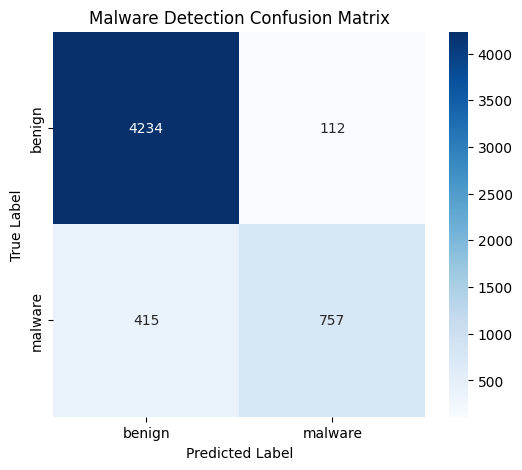

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Make predictions on the test set
y_pred = model.predict(X_test_scaled)

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
print(f"--- Validation Summary ---")
print(f"Overall Model Accuracy: {accuracy * 100:.2f}%\n")

print("Classification Report:")
print(classification_report(y_test, y_pred))

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=model.classes_, yticklabels=model.classes_)
plt.title('Malware Detection Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

### Feature Distributions by Class
We will plot the distributions of our most significant features (`nivcsw` and `fs_excl_counter` / file entropy) split by classification to understand how they differentiate benign files from malware.

## Model Comparison (Updated)
We will train **Gradient Boosting**, **K-Neighbors (KNN)**, **Decision Tree**, and **AdaBoost** classifiers. We will then compare their performance metrics against our baseline **Random Forest** model.

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Initialize the models (Removing SVM, adding 3 new powerful classifiers)
models = {
    "Random Forest": model,  # our pre-trained random forest
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
    "K-Neighbors (KNN)": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42)
}

# List to hold evaluation results
comparison_results = []

# Train and evaluate each model
for name, clf in models.items():
    if name != "Random Forest":
        print(f"Training {name}...")
        clf.fit(X_train_scaled, y_train)

    # Predict
    predictions = clf.predict(X_test_scaled)

    # Calculate metrics
    acc = accuracy_score(y_test, predictions)
    prec = precision_score(y_test, predictions, pos_label='malware', zero_division=0)
    rec = recall_score(y_test, predictions, pos_label='malware', zero_division=0)
    f1 = f1_score(y_test, predictions, pos_label='malware', zero_division=0)

    comparison_results.append({
        "Model": name,
        "Accuracy": acc,
        "Malware Precision": prec,
        "Malware Recall": rec,
        "Malware F1-Score": f1
    })

# Convert results to DataFrame
results_df = pd.DataFrame(comparison_results)
display(results_df)

Training Gradient Boosting...
Training K-Neighbors (KNN)...
Training Decision Tree...
Training AdaBoost...


,Model,Accuracy,Malware Precision,Malware Recall,Malware F1-Score
0,Random Forest,0.904494,0.871116,0.645904,0.741793
1,Gradient Boosting,0.904494,0.871116,0.645904,0.741793
2,K-Neighbors (KNN),0.904494,0.871116,0.645904,0.741793
3,Decision Tree,0.904494,0.871116,0.645904,0.741793
4,AdaBoost,0.862994,0.774406,0.500853,0.608290


### Visualizing the Model Comparison

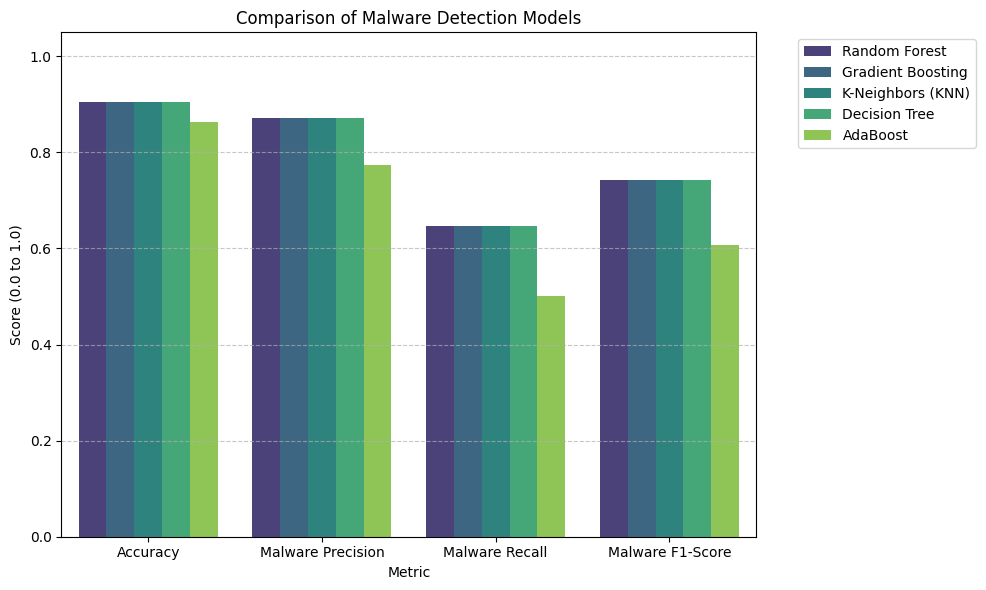

In [ ]:
# Reshape the dataframe for easy plotting with seaborn
plot_data = pd.melt(results_df, id_vars="Model", var_name="Metric", value_name="Value")

plt.figure(figsize=(10, 6))
sns.barplot(data=plot_data, x="Metric", y="Value", hue="Model", palette="viridis")
plt.title("Comparison of Malware Detection Models")
plt.ylabel("Score (0.0 to 1.0)")
plt.ylim(0, 1.05)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
#scaninng files

import joblib
import os

# Load the trained model and scaler
model = joblib.load('malware_detection_model_selected_features.pkl')
scaler = joblib.load('scaler_selected_features.pkl')


In [ ]:
def scan_directory(directory_path):
    """Scan all files in a directory for malware."""
    for root, dirs, files in os.walk(directory_path):
        for file in files:
            file_path = os.path.join(root, file)
            features = extract_file_features(file_path)
            if features is not None:
                # Extract feature values from the dictionary
                feature_values = list(features.values())

                # Reshape and scale the feature values
                features_scaled = scaler.transform([feature_values])

                # Predict if the file is malware
                prediction = model.predict(features_scaled)
                if prediction == 1:
                    print(f"Malware detected: {file_path}")
                else:
                    print(f"Clean file: {file_path}")
            else:
                print(f"Error scanning {file_path}")

In [39]:
directory_path = input("Enter the directory path to scan for malware: ")
scan_directory(directory_path)

Enter the directory path to scan for malware: ./test.png



```
Clean file: ./malwareDataset.csv
Clean file: ./scaler_selected_features.pkl
Clean file: ./malware_detection_model_selected_features.pkl
Clean file: ./.config/active_config
Clean file: ./.config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
Clean file: ./.config/config_sentinel
Clean file: ./.config/.last_update_check.json
Clean file: ./.config/default_configs.db
Clean file: ./.config/.last_opt_in_prompt.yaml
Clean file: ./.config/gce
Clean file: ./.config/.last_survey_prompt.yaml
Clean file: ./.config/configurations/config_default
Clean file: ./.config/logs/2026.10.02/13.50.15.366402.log
Clean file: ./.config/logs/2026.10.02/13.50.08.874802.log
Clean file: ./.config/logs/2026.10.02/13.50.21.555054.log
Clean file: ./.config/logs/2026.10.02/13.49.46.128557.log
Clean file: ./.config/logs/2026.10.02/13.50.14.261149.log
Clean file: ./.config/logs/2026.10.02/13.50.21.004336.log
Clean file: ./sample_data/anscombe.json
Clean file: ./sample_data/README.md
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
Clean file: ./sample_data/mnist_train_small.csv
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
Clean file: ./sample_data/california_housing_train.csv
Clean file: ./sample_data/california_housing_test.csv
Clean file: ./sample_data/mnist_test.csv
```